# Water potability: a reproducible analysis

Can nine physico-chemical measurements tell us whether a water sample is safe to drink?

**What this notebook does, in order**

1. Load and explore the data (missing values, class balance, how much the two classes differ).
2. Hold out a test set (20%) that is touched **once**, at the very end.
3. Compare three models with 5-fold cross-validation on the remaining 80%. Imputation lives inside each model pipeline, so no fold ever sees statistics computed on its own validation data.
4. Tune the best model family with cross-validation.
5. Choose the decision threshold from out-of-fold predictions, with a safety-first objective.
6. Evaluate the final model once on the test set.

**Why precision for "potable" is the metric that matters.** The costly mistake is a *false positive*:
declaring unsafe water potable. So the threshold is chosen to keep **precision for the potable class**
at or above a target (default 0.75: at most 1 in 4 samples labelled "potable" is actually unsafe),
and among those thresholds we take the one with the highest recall.

Run with *Restart & Run all*. Everything uses `RANDOM_STATE = 42`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
TARGET_PRECISION = 0.75  # minimum precision for the "potable" class; change to taste
DATA_PATH = Path("data/water_potability.csv")

sns.set_theme(style="whitegrid")

## 1. Data

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [3]:
summary = pd.DataFrame({
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(1),
})
summary.join(df.describe().T[["mean", "std", "min", "max"]].round(2))

,missing,missing_%,mean,std,min,max
ph,491,15.0,7.08,1.59,0.00,14.00
Hardness,0,0.0,196.37,32.88,47.43,323.12
Solids,0,0.0,22014.09,8768.57,320.94,61227.20
Chloramines,0,0.0,7.12,1.58,0.35,13.13
Sulfate,781,23.8,333.78,41.42,129.00,481.03
Conductivity,0,0.0,426.21,80.82,181.48,753.34
Organic_carbon,0,0.0,14.28,3.31,2.20,28.30
Trihalomethanes,162,4.9,66.40,16.18,0.74,124.00
Turbidity,0,0.0,3.97,0.78,1.45,6.74
Potability,0,0.0,0.39,0.49,0.00,1.00


Potability
not potable (0)    1998
potable (1)        1278
Name: count, dtype: int64
Share potable: 39.0%


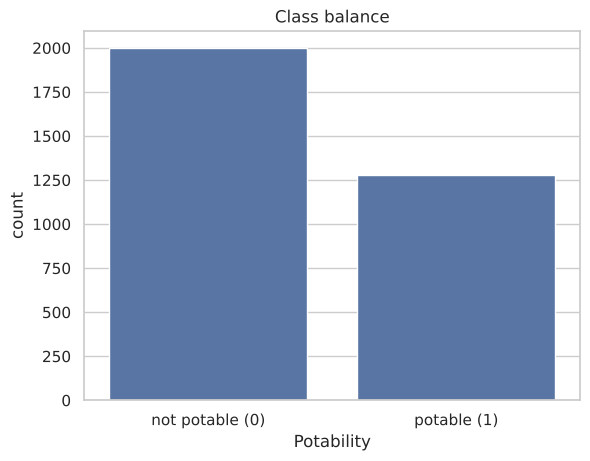

In [4]:
counts = df["Potability"].value_counts().sort_index()
print(counts.rename({0: "not potable (0)", 1: "potable (1)"}))
print(f"Share potable: {counts[1] / counts.sum():.1%}")

ax = sns.countplot(data=df, x="Potability")
ax.set_xticks([0, 1], ["not potable (0)", "potable (1)"])
ax.set_title("Class balance")
plt.show()

### How different are the two classes?

If the features carried a strong signal, the class means and distributions would differ visibly.

In [5]:
features = [c for c in df.columns if c != "Potability"]
means = df.groupby("Potability")[features].mean().T
means.columns = ["mean (not potable)", "mean (potable)"]
means["relative difference %"] = ((means.iloc[:, 1] - means.iloc[:, 0]) / means.iloc[:, 0] * 100).round(2)
means.round(2)

,mean (not potable),mean (potable),relative difference %
ph,7.09,7.07,-0.16
Hardness,196.73,195.80,-0.47
Solids,21777.49,22383.99,2.78
Chloramines,7.09,7.17,1.09
Sulfate,334.56,332.57,-0.60
Conductivity,426.73,425.38,-0.32
Organic_carbon,14.36,14.16,-1.42
Trihalomethanes,66.30,66.54,0.36
Turbidity,3.97,3.97,0.06


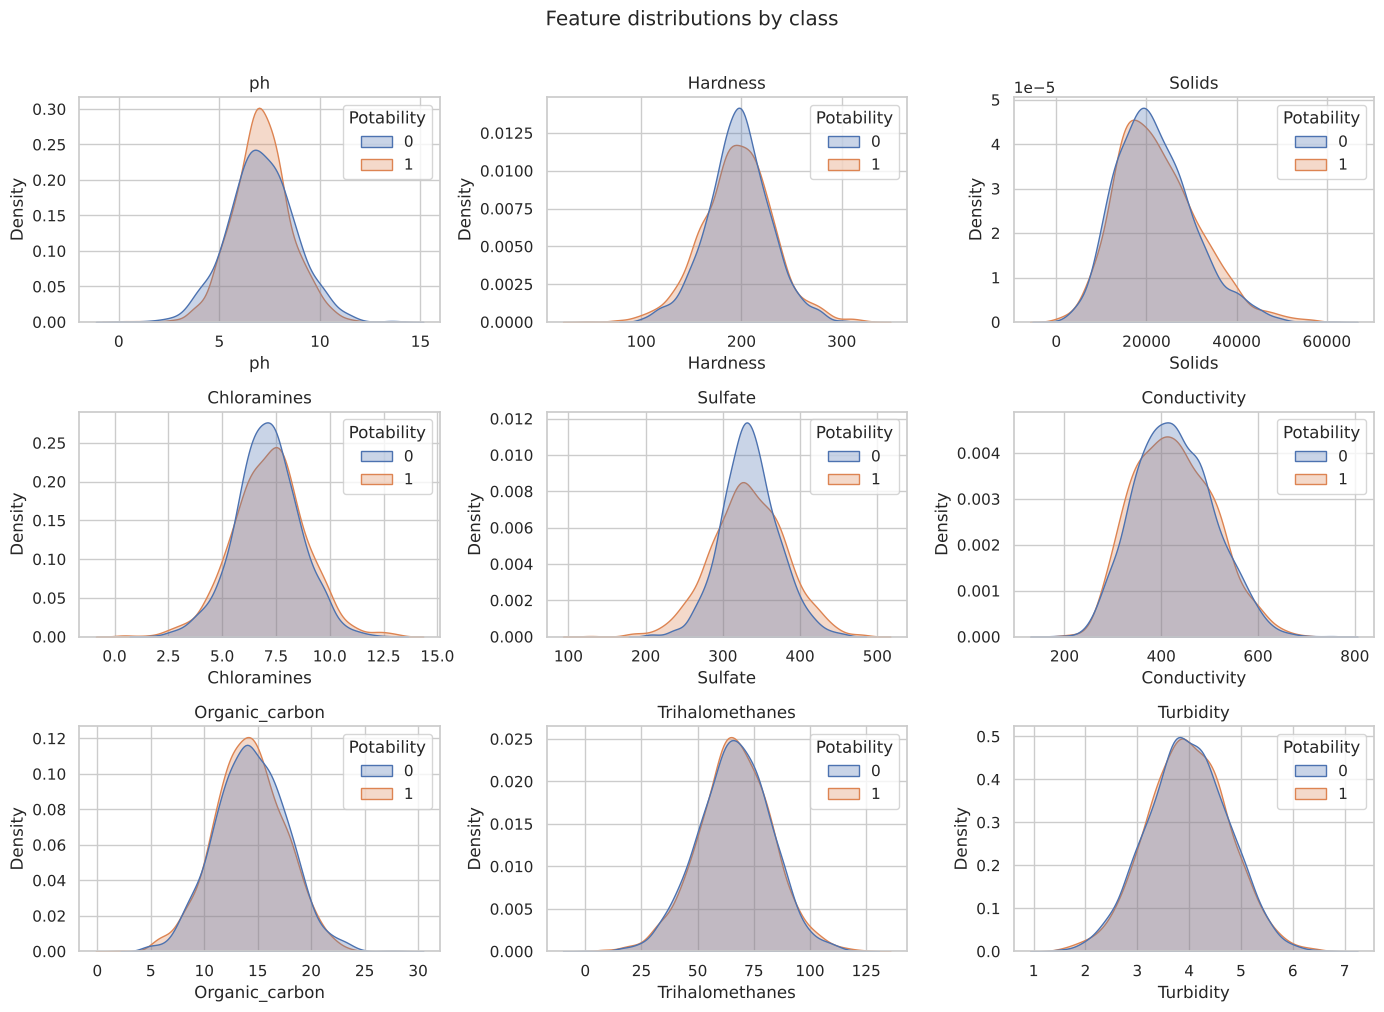

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.ravel(), features):
    sns.kdeplot(data=df, x=col, hue="Potability", common_norm=False, fill=True, alpha=0.3, ax=ax)
    ax.set_title(col)
plt.suptitle("Feature distributions by class", y=1.01)
plt.tight_layout()
plt.show()

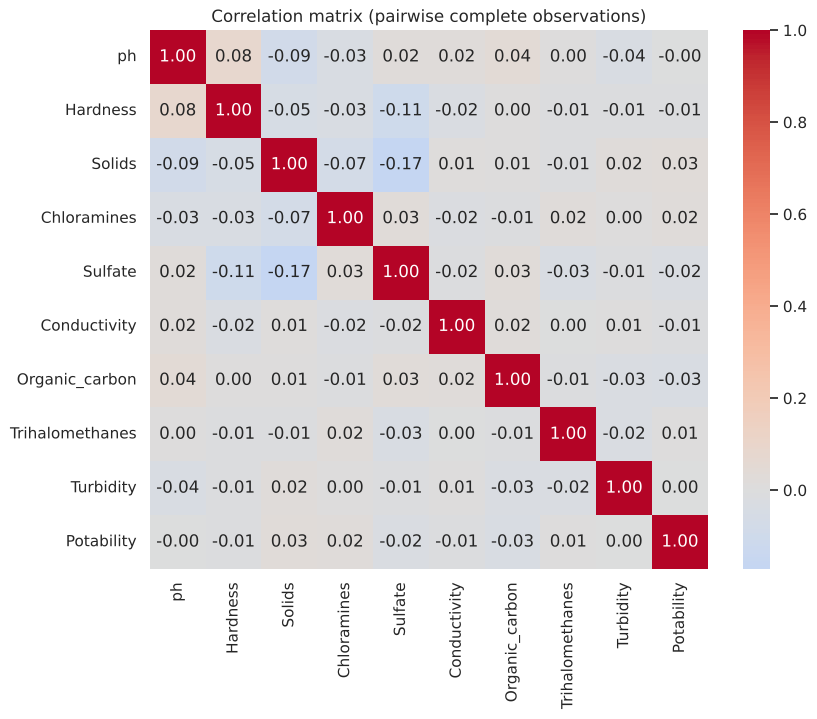

In [7]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (pairwise complete observations)")
plt.show()

**Reading the plots.** The two classes have almost identical means and overlapping distributions, and every
feature has a near-zero correlation with `Potability`. Expect a modest ceiling on performance (ROC-AUC
around 0.65 to 0.70), and expect linear models to do no better than chance. Note also that some values do
not match real drinking-water guidance (for example `Solids` averages ~22,000 ppm, far above the
WHO-recommended range for total dissolved solids), so this public dataset is best treated as a teaching dataset,
not a basis for real potability decisions.

## 2. Hold out the test set

In [8]:
X = df[features]
y = df["Potability"]

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"Development set: {len(X_dev)} rows | Test set: {len(X_test)} rows (not used until section 6)")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Development set: 2620 rows | Test set: 656 rows (not used until section 6)


## 3. Compare model families with cross-validation

All models share the same preprocessing: median imputation fitted inside each training fold, plus missing-value
indicator columns (so the model can use "this value was missing" if that is informative).

In [9]:
def imputer():
    return SimpleImputer(strategy="median", add_indicator=True)

candidates = {
    "Logistic Regression": make_pipeline(
        imputer(), StandardScaler(),
        LogisticRegression(max_iter=1000, class_weight="balanced"),
    ),
    "Random Forest": make_pipeline(
        imputer(),
        RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    ),
    # HistGradientBoosting handles NaN natively, so it needs no imputer
    "Gradient Boosting": HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=300, class_weight="balanced", random_state=RANDOM_STATE
    ),
}

rows = []
for name, model in candidates.items():
    scores = cross_validate(model, X_dev, y_dev, cv=cv, scoring=["roc_auc", "average_precision"], n_jobs=-1)
    rows.append({
        "model": name,
        "ROC-AUC mean": scores["test_roc_auc"].mean(),
        "ROC-AUC std": scores["test_roc_auc"].std(),
        "PR-AUC mean": scores["test_average_precision"].mean(),
    })
cv_results = pd.DataFrame(rows).set_index("model").round(3)
print(f"Chance-level PR-AUC = share of potable = {y_dev.mean():.3f}")
cv_results

Chance-level PR-AUC = share of potable = 0.390


,ROC-AUC mean,ROC-AUC std,PR-AUC mean
model,,,
Logistic Regression,0.486,0.021,0.400
Random Forest,0.685,0.016,0.597
Gradient Boosting,0.665,0.016,0.576


## 4. Tune the best family (Random Forest) with cross-validation

In [10]:
rf_pipeline = make_pipeline(
    imputer(),
    RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
)
param_grid = {
    "randomforestclassifier__max_depth": [None, 20],
    "randomforestclassifier__min_samples_leaf": [1, 2, 4],
    "randomforestclassifier__max_features": ["sqrt", 0.5],
}
search = GridSearchCV(rf_pipeline, param_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
search.fit(X_dev, y_dev)

print("Best parameters:", search.best_params_)
print(f"Best CV ROC-AUC: {search.best_score_:.3f}")
best_model = search.best_estimator_

Best parameters: {'randomforestclassifier__max_depth': None, 'randomforestclassifier__max_features': 0.5, 'randomforestclassifier__min_samples_leaf': 2}
Best CV ROC-AUC: 0.698


## 5. Choose the decision threshold (out-of-fold, no test data)

Out-of-fold probabilities: every development row is scored by a model that did not see it in training.
We then pick the threshold with the highest recall among those whose precision for "potable" is at least
`TARGET_PRECISION`.

Chosen threshold: 0.629
Out-of-fold precision (potable): 0.750 | recall (potable): 0.217


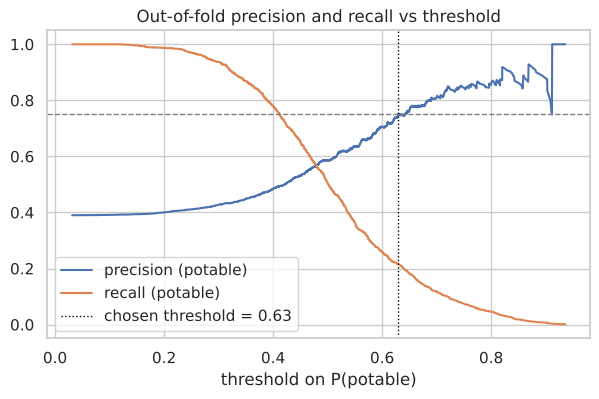

In [11]:
oof_proba = cross_val_predict(best_model, X_dev, y_dev, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_dev, oof_proba)

ok = precision[:-1] >= TARGET_PRECISION
if not ok.any():
    raise ValueError(f"No threshold reaches precision {TARGET_PRECISION}; lower TARGET_PRECISION.")
idx = np.flatnonzero(ok)[np.argmax(recall[:-1][ok])]
threshold = thresholds[idx]

print(f"Chosen threshold: {threshold:.3f}")
print(f"Out-of-fold precision (potable): {precision[idx]:.3f} | recall (potable): {recall[idx]:.3f}")

plt.figure(figsize=(7, 4))
plt.plot(thresholds, precision[:-1], label="precision (potable)")
plt.plot(thresholds, recall[:-1], label="recall (potable)")
plt.axhline(TARGET_PRECISION, color="grey", ls="--", lw=1)
plt.axvline(threshold, color="black", ls=":", lw=1, label=f"chosen threshold = {threshold:.2f}")
plt.xlabel("threshold on P(potable)")
plt.title("Out-of-fold precision and recall vs threshold")
plt.legend()
plt.show()

## 6. Final evaluation on the test set (run once)

In [12]:
best_model.fit(X_dev, y_dev)
test_proba = best_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, test_pred).ravel()
final = pd.Series({
    "ROC-AUC": roc_auc_score(y_test, test_proba),
    "PR-AUC": average_precision_score(y_test, test_proba),
    "precision (potable)": precision_score(y_test, test_pred),
    "recall (potable)": recall_score(y_test, test_pred),
    "unsafe samples called potable (FP)": fp,
    "share of unsafe samples called potable": fp / (fp + tn),
}).round(3)
final

ROC-AUC                                    0.667
PR-AUC                                     0.608
precision (potable)                        0.803
recall (potable)                           0.223
unsafe samples called potable (FP)        14.000
share of unsafe samples called potable     0.035
dtype: float64

              precision    recall  f1-score   support

 not potable       0.66      0.96      0.78       400
     potable       0.80      0.22      0.35       256

    accuracy                           0.68       656
   macro avg       0.73      0.59      0.57       656
weighted avg       0.72      0.68      0.61       656



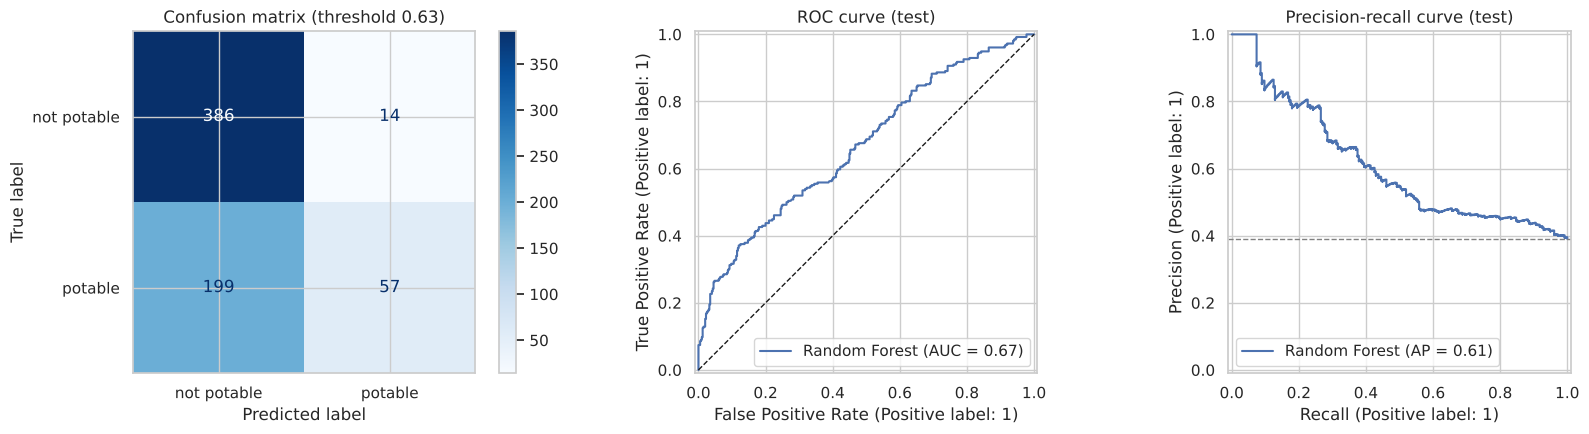

In [13]:
print(classification_report(y_test, test_pred, target_names=["not potable", "potable"]))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=["not potable", "potable"], cmap="Blues", ax=axes[0]
)
axes[0].set_title(f"Confusion matrix (threshold {threshold:.2f})")
RocCurveDisplay.from_predictions(y_test, test_proba, ax=axes[1], name="Random Forest")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_title("ROC curve (test)")
PrecisionRecallDisplay.from_predictions(y_test, test_proba, ax=axes[2], name="Random Forest")
axes[2].axhline(y_test.mean(), color="grey", ls="--", lw=1, label="chance")
axes[2].set_title("Precision-recall curve (test)")
plt.tight_layout()
plt.show()

### Which features matter?

Permutation importance on the test set: how much ROC-AUC drops when one feature is shuffled.
It is unbiased with respect to feature scale and cardinality, unlike the impurity-based `feature_importances_`.

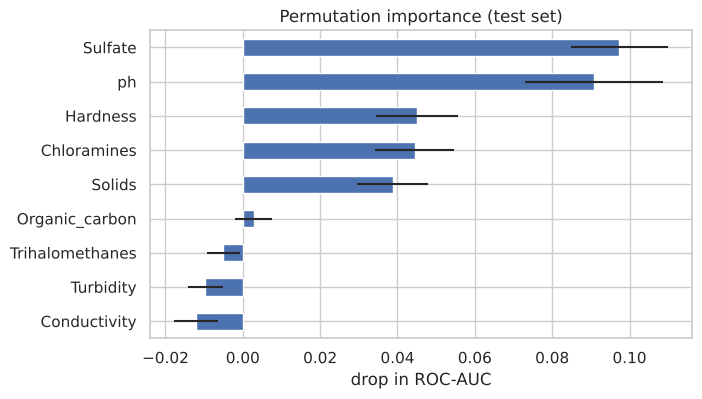

,mean drop in ROC-AUC,std
Sulfate,0.0974,0.0125
ph,0.0908,0.0177
Hardness,0.0450,0.0105
Chloramines,0.0444,0.0101
Solids,0.0387,0.0092
Organic_carbon,0.0028,0.0048
Trihalomethanes,-0.0050,0.0042
Turbidity,-0.0096,0.0045
Conductivity,-0.0121,0.0056


In [14]:
perm = permutation_importance(
    best_model, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1
)
importance = pd.DataFrame(
    {"mean drop in ROC-AUC": perm.importances_mean, "std": perm.importances_std}, index=features
).sort_values("mean drop in ROC-AUC", ascending=False)

importance["mean drop in ROC-AUC"].plot.barh(xerr=importance["std"], figsize=(7, 4))
plt.gca().invert_yaxis()
plt.title("Permutation importance (test set)")
plt.xlabel("drop in ROC-AUC")
plt.show()
importance.round(4)

## 7. Conclusions

- Linear models are at chance level on this data; tree ensembles find a weak, non-linear signal (ROC-AUC about 0.65 to 0.70).
- Permutation importance points to `Sulfate` and `ph` as the most useful features. Their class means are identical,
  so the signal is non-linear (for example, extreme values on either side), which is why linear models miss it.
- With a safety-first threshold, the model can flag only a minority of the potable samples while keeping
  precision for "potable" near the target. That is the honest trade-off this dataset allows.
- The dataset itself is the main limitation: the classes barely differ on any single feature and several
  values do not match real drinking-water guidance. Results should not be used for real potability decisions.

**Possible next steps:** calibrate probabilities (`CalibratedClassifierCV`), test whether domain thresholds
(e.g. pH 6.5 to 8.5) add signal, and validate on a real, documented water-quality dataset.